In [4]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from pathlib import Path
import torch

from meles.frame_aggregation.facial import Facial

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
from meles.dataset import read_dataset

DATASET_PATH = Path("../../data")

# Iterate all directories and create the dataframe. The structure should be 'identity/video/frame'
structure = pd.read_parquet(DATASET_PATH / "ytfaces.parquet")
structure

,identity,video,frame,frame_suffix,path
0,Aaron_Eckhart,0,aligned_detect_0.555.jpg,.jpg,ytfaces/Aaron_Eckhart/0/aligned_detect_0.555.jpg
1,Aaron_Eckhart,0,aligned_detect_0.556.jpg,.jpg,ytfaces/Aaron_Eckhart/0/aligned_detect_0.556.jpg
2,Aaron_Eckhart,0,aligned_detect_0.557.jpg,.jpg,ytfaces/Aaron_Eckhart/0/aligned_detect_0.557.jpg
3,Aaron_Eckhart,0,aligned_detect_0.558.jpg,.jpg,ytfaces/Aaron_Eckhart/0/aligned_detect_0.558.jpg
4,Aaron_Eckhart,0,aligned_detect_0.559.jpg,.jpg,ytfaces/Aaron_Eckhart/0/aligned_detect_0.559.jpg
...,...,...,...,...,...
130722,Zulfiqar_Ahmed,4,aligned_detect_4.225.jpg,.jpg,ytfaces/Zulfiqar_Ahmed/4/aligned_detect_4.225.jpg
130723,Zulfiqar_Ahmed,4,aligned_detect_4.226.jpg,.jpg,ytfaces/Zulfiqar_Ahmed/4/aligned_detect_4.226.jpg
130724,Zulfiqar_Ahmed,4,aligned_detect_4.227.jpg,.jpg,ytfaces/Zulfiqar_Ahmed/4/aligned_detect_4.227.jpg
130725,Zulfiqar_Ahmed,4,aligned_detect_4.228.jpg,.jpg,ytfaces/Zulfiqar_Ahmed/4/aligned_detect_4.228.jpg


In [3]:
from meles.frame_embedder import FrameEmbedder, models

# TODO for each video, select the image with the largest ArcFace norm
arcface = FrameEmbedder(models.ARCFACE)

structure_paths = [str(Path("../../data") / path) for path in structure["path"]]
structure["embedding"] = arcface.embed(structure_paths)
structure

/data/projects/personal/meles/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Embedding (ArcFace): 100%|██████████| 130727/130727 [15:37<00:00, 139.39frame/s]


,identity,video,frame,frame_suffix,path,embedding
0,Aaron_Eckhart,0,aligned_detect_0.555.jpg,.jpg,ytfaces/Aaron_Eckhart/0/aligned_detect_0.555.jpg,"[0.5889215469360352, -1.519578218460083, 0.802..."
1,Aaron_Eckhart,0,aligned_detect_0.556.jpg,.jpg,ytfaces/Aaron_Eckhart/0/aligned_detect_0.556.jpg,"[0.9360359907150269, -1.241746187210083, 1.154..."
2,Aaron_Eckhart,0,aligned_detect_0.557.jpg,.jpg,ytfaces/Aaron_Eckhart/0/aligned_detect_0.557.jpg,"[0.6813623309135437, -1.126441478729248, 0.347..."
3,Aaron_Eckhart,0,aligned_detect_0.558.jpg,.jpg,ytfaces/Aaron_Eckhart/0/aligned_detect_0.558.jpg,"[0.3238150179386139, -0.023174799978733063, -0..."
4,Aaron_Eckhart,0,aligned_detect_0.559.jpg,.jpg,ytfaces/Aaron_Eckhart/0/aligned_detect_0.559.jpg,"[-0.4572497010231018, -0.9873819351196289, 0.8..."
...,...,...,...,...,...,...
130722,Zulfiqar_Ahmed,4,aligned_detect_4.225.jpg,.jpg,ytfaces/Zulfiqar_Ahmed/4/aligned_detect_4.225.jpg,"[-0.05851766839623451, -0.6751792430877686, -0..."
130723,Zulfiqar_Ahmed,4,aligned_detect_4.226.jpg,.jpg,ytfaces/Zulfiqar_Ahmed/4/aligned_detect_4.226.jpg,"[-0.05851766839623451, -0.6751792430877686, -0..."
130724,Zulfiqar_Ahmed,4,aligned_detect_4.227.jpg,.jpg,ytfaces/Zulfiqar_Ahmed/4/aligned_detect_4.227.jpg,"[-0.23919226229190826, 0.01733105070888996, -1..."
130725,Zulfiqar_Ahmed,4,aligned_detect_4.228.jpg,.jpg,ytfaces/Zulfiqar_Ahmed/4/aligned_detect_4.228.jpg,"[-0.23919226229190826, 0.01733105070888996, -1..."


In [5]:
structure["confidence"] = structure["embedding"].apply(lambda embedding: np.linalg.norm(embedding))
structure

,identity,video,frame,frame_suffix,path,embedding,confidence
0,Aaron_Eckhart,0,aligned_detect_0.555.jpg,.jpg,ytfaces/Aaron_Eckhart/0/aligned_detect_0.555.jpg,"[0.5889215469360352, -1.519578218460083, 0.802...",26.698917
1,Aaron_Eckhart,0,aligned_detect_0.556.jpg,.jpg,ytfaces/Aaron_Eckhart/0/aligned_detect_0.556.jpg,"[0.9360359907150269, -1.241746187210083, 1.154...",26.228217
2,Aaron_Eckhart,0,aligned_detect_0.557.jpg,.jpg,ytfaces/Aaron_Eckhart/0/aligned_detect_0.557.jpg,"[0.6813623309135437, -1.126441478729248, 0.347...",26.472415
3,Aaron_Eckhart,0,aligned_detect_0.558.jpg,.jpg,ytfaces/Aaron_Eckhart/0/aligned_detect_0.558.jpg,"[0.3238150179386139, -0.023174799978733063, -0...",26.395938
4,Aaron_Eckhart,0,aligned_detect_0.559.jpg,.jpg,ytfaces/Aaron_Eckhart/0/aligned_detect_0.559.jpg,"[-0.4572497010231018, -0.9873819351196289, 0.8...",24.880782
...,...,...,...,...,...,...,...
130722,Zulfiqar_Ahmed,4,aligned_detect_4.225.jpg,.jpg,ytfaces/Zulfiqar_Ahmed/4/aligned_detect_4.225.jpg,"[-0.05851766839623451, -0.6751792430877686, -0...",25.207157
130723,Zulfiqar_Ahmed,4,aligned_detect_4.226.jpg,.jpg,ytfaces/Zulfiqar_Ahmed/4/aligned_detect_4.226.jpg,"[-0.05851766839623451, -0.6751792430877686, -0...",25.207157
130724,Zulfiqar_Ahmed,4,aligned_detect_4.227.jpg,.jpg,ytfaces/Zulfiqar_Ahmed/4/aligned_detect_4.227.jpg,"[-0.23919226229190826, 0.01733105070888996, -1...",26.348792
130725,Zulfiqar_Ahmed,4,aligned_detect_4.228.jpg,.jpg,ytfaces/Zulfiqar_Ahmed/4/aligned_detect_4.228.jpg,"[-0.23919226229190826, 0.01733105070888996, -1...",26.348792


In [6]:
candidates = structure.loc[structure.groupby(['identity', 'video'])['confidence'].idxmax()]
candidates

,identity,video,frame,frame_suffix,path,embedding,confidence
0,Aaron_Eckhart,0,aligned_detect_0.555.jpg,.jpg,ytfaces/Aaron_Eckhart/0/aligned_detect_0.555.jpg,"[0.5889215469360352, -1.519578218460083, 0.802...",26.698917
116,Aaron_Eckhart,1,aligned_detect_1.224.jpg,.jpg,ytfaces/Aaron_Eckhart/1/aligned_detect_1.224.jpg,"[0.020532313734292984, -0.9730352163314819, 0....",25.354717
179,Aaron_Eckhart,2,aligned_detect_2.1773.jpg,.jpg,ytfaces/Aaron_Eckhart/2/aligned_detect_2.1773.jpg,"[1.5178141593933105, -0.6531201601028442, 2.95...",25.493594
244,Abdel_Aziz_Al-Hakim,0,aligned_detect_0.961.jpg,.jpg,ytfaces/Abdel_Aziz_Al-Hakim/0/aligned_detect_0...,"[-0.45584535598754883, 0.38075587153434753, -0...",25.635145
328,Abdel_Aziz_Al-Hakim,1,aligned_detect_1.478.jpg,.jpg,ytfaces/Abdel_Aziz_Al-Hakim/1/aligned_detect_1...,"[2.0791709423065186, -0.763652503490448, 0.029...",23.661269
...,...,...,...,...,...,...,...
130410,Zoran_Djindjic,1,aligned_detect_1.130.jpg,.jpg,ytfaces/Zoran_Djindjic/1/aligned_detect_1.130.jpg,"[1.2287932634353638, -1.042264461517334, 1.256...",24.180518
130473,Zoran_Djindjic,2,aligned_detect_2.1987.jpg,.jpg,ytfaces/Zoran_Djindjic/2/aligned_detect_2.1987...,"[-0.24470214545726776, -1.350044846534729, 0.9...",25.195558
130542,Zulfiqar_Ahmed,1,aligned_detect_1.1985.jpg,.jpg,ytfaces/Zulfiqar_Ahmed/1/aligned_detect_1.1985...,"[0.6771853566169739, 0.163016214966774, -1.873...",25.706536
130602,Zulfiqar_Ahmed,2,aligned_detect_2.1058.jpg,.jpg,ytfaces/Zulfiqar_Ahmed/2/aligned_detect_2.1058...,"[-2.053682327270508, 0.8784841299057007, -0.91...",27.366787


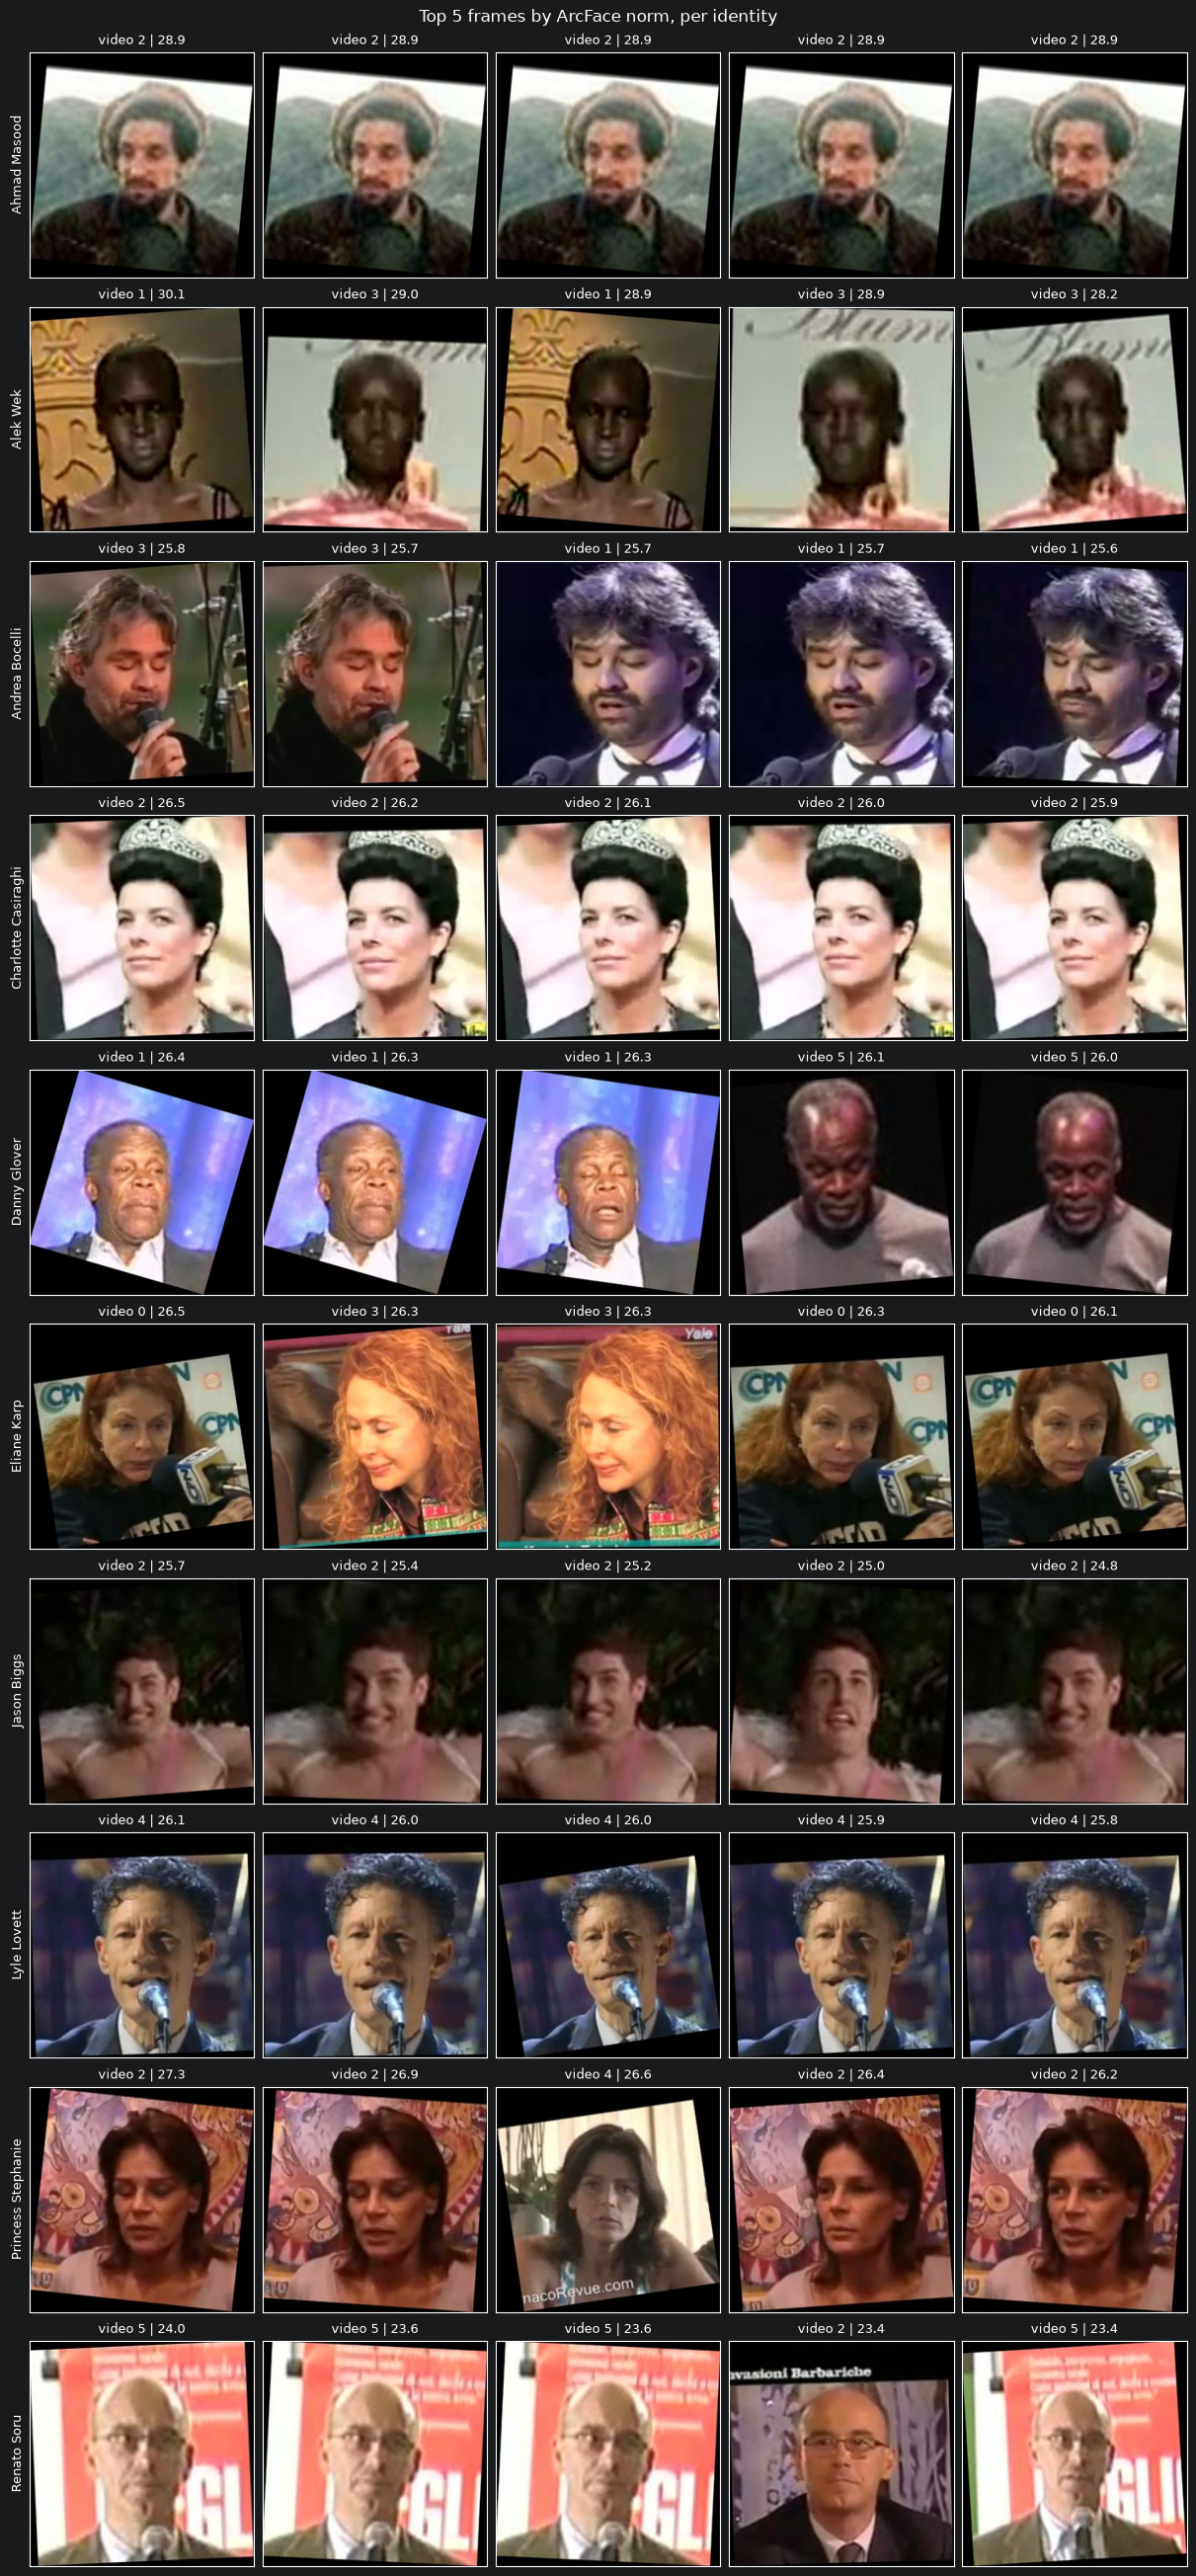

In [8]:
import cv2

TOP_K = 5  # frames shown per identity
N_IDENTITIES = 10  # identities sampled for the grid

# Sample identities rather than rows, so each row of the grid is one person. Seeded so the
# figure is stable across reruns.
rng = np.random.default_rng(0)
identities = rng.choice(np.sort(structure["identity"].unique()), size=N_IDENTITIES, replace=False)

# The best TOP_K frames the identity has anywhere, ranked over all of its videos at once. The
# winners are often neighbouring frames of one shot, which is what the ranking is supposed to say.
samples = (
    structure[structure["identity"].isin(identities)]
    .sort_values(["identity", "confidence"], ascending=[True, False])
    .groupby("identity", sort=False)
    .head(TOP_K)
)

fig, axes = plt.subplots(
    N_IDENTITIES,
    TOP_K,
    figsize=(2.4 * TOP_K, 2.6 * N_IDENTITIES),
    squeeze=False,
    layout="constrained",
)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

for row, (identity, group) in enumerate(samples.groupby("identity", sort=False)):
    for col, (_, frame) in enumerate(group.iterrows()):
        ax = axes[row, col]
        image = cv2.imread(str(DATASET_PATH / frame["path"]))
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(f"video {frame['video']} | {frame['confidence']:.1f}", fontsize=9)

    # An identity with fewer than TOP_K frames leaves its trailing cells empty.
    for col in range(len(group), TOP_K):
        axes[row, col].set_axis_off()

    axes[row, 0].set_ylabel(identity.replace("_", " "), fontsize=9)

fig.suptitle(f"Top {TOP_K} frames by ArcFace norm, per identity", fontsize=12)
plt.show()

In [ ]:
model = Facial(weights="backbone.pth").cuda()

In [2]:
# Stage 1

model.set_encoder_frozen(True)
opt = torch.optim.AdamW(model.train_parameters(), lr=1e-4, weight_decay=5e-4)

In [ ]:
# Stage 2

model.set_encoder_frozen(False)
opt = torch.optim.AdamW([
    {"params": model.fine_parameters(), "lr": 1e-5},
    {"params": model.train_parameters(), "lr": 1e-4},
], weight_decay=5e-4)